# Session Title: Artificial Netural Networks for classification

**Instructor:** Zahra Sadeghi

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score

Generate and visualize the data

**Create the dataset**

In [ ]:
X, y = make_moons(
    n_samples=500,
    noise=0.2,
    random_state=42 # controls the randomness, allowing you to reproduce experiments and obtain consistent results when you run the same code under the same conditions.
)


In [ ]:
print(X[:10])

[[ 0.83085779 -0.33434228]
 [ 0.99170955  0.87899966]
 [ 1.1072453  -0.47034376]
 [-0.14089918  1.03314844]
 [ 0.40559217  1.32852876]
 [ 1.28895069 -0.52407983]
 [ 1.12079473 -0.27225413]
 [ 0.10659373  1.21210782]
 [ 0.5201985   0.58288335]
 [ 1.70590095 -0.33306612]]


In [ ]:
print(y[:10])

[1 0 1 0 0 1 1 0 0 1]


Visualize the data --- "We have a binary classification problem with two nonlinear classes. Our goal is to learn a decision boundary that separates them."

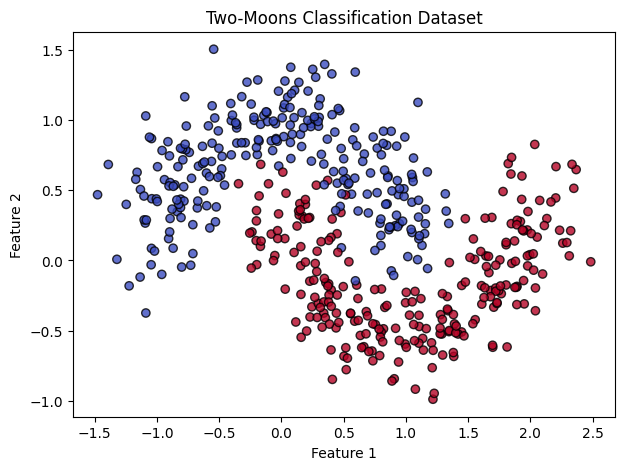

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolor="k",
    alpha=0.8
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two-Moons Classification Dataset")

plt.show()


4. Create the K-Fold Cross-Validation strategy: "We divide the data into five folds. In each iteration, four folds are used for training and one fold is used for validation."

In [ ]:
# stratification does not balance the dataset. It preserves approximately the original class proportions.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


**Define a baseline MLP**

With solver="sgd", scikit-learn uses mini-batch gradient-based optimization by default. The default batch_size is "auto", which means: min(200, n_samples)

In [ ]:
mlp = MLPClassifier(
    hidden_layer_sizes=(10, 10),
    activation="relu",
    solver="sgd",
    alpha=0.0001, # L2 Regularization strength
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=42
)


Create a Pipeline: "The Pipeline ensures that preprocessing and model training happen together. During K-Fold Cross-Validation, the scaler is fitted only on the training portion of each fold, preventing data leakage."

StandardScaler standardizes each input feature so that it has approximately:

    Mean = 0
    Standard deviation = 1

    z=(x−μ)/σ

In [ ]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", mlp)
])


create the train/test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


Perform 5-Fold Cross-Validation

In [ ]:
np.shape(X),np.shape(X_train),np.shape(X_test)

((400, 2), (100, 2), (500, 2))

In [ ]:
scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("CV F1 scores:", scores)

print("\nMean accuracy:")
print(scores.mean())

print("\nStandard deviation:")
print(scores.std())


CV F1 scores: [0.975      0.97435897 0.98734177 0.98765432 0.97560976]
Mean CV F1: 0.9799929647192176

Mean accuracy:
0.9799929647192176

Standard deviation:
0.006141423490399843



    "This MLP works reasonably well."

    "But are these hyperparameters optimal?"


Grid Search with 5-Fold CV. GridSearchCV asks: "Which combination of hyperparameters gives me the best cross-validated F1 score?"



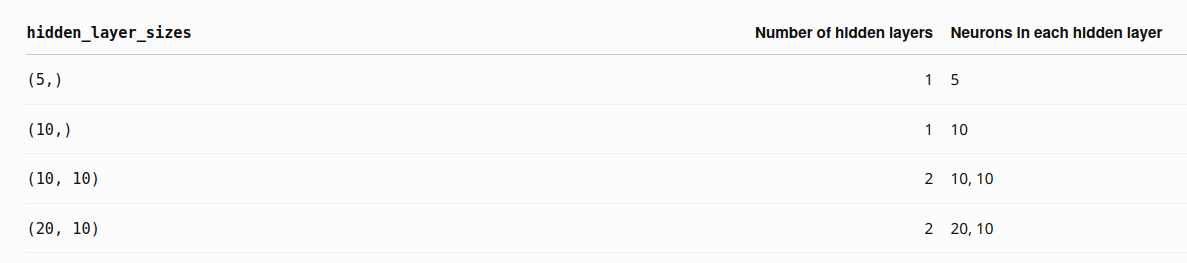hidden_layer_sizes	Number of hidden layers	Neurons in each hidden layer
(5,)	1	5
(10,)	1	10
(10, 10)	2	10, 10
(20, 10)	2	20, 10

In [ ]:
param_grid = {
    "mlp__hidden_layer_sizes": [
        (5,),
        (10,),
        (10, 10),
        (20, 10)
    ],

    "mlp__alpha": [
        0.0001,
        0.001,
        0.01
    ], #L2 regularization strength

    "mlp__learning_rate_init": [
        0.001,
        0.01
    ]
}


In [ ]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    model,
    param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1 #use all available CPU cores
)


Find the best configuration:

In [ ]:
grid_search.fit(X_train, y_train)


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('mlp',
                                        MLPClassifier(hidden_layer_sizes=(10,
                                                                          10),
                                                      max_iter=1000,
                                                      random_state=42))]),
             n_jobs=-1,
             param_grid={'mlp__alpha': [0.0001, 0.001, 0.01],
                         'mlp__hidden_layer_sizes': [(5,), (10,), (10, 10),
                                                     (20, 10)],
                         'mlp__learning_rate_init': [0.001, 0.01]},
             scoring='f1')

GridSearchCV already trained using best parameters

In [ ]:
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV F1-score:") #mean cross-validation score for the best-performing hyperparameter combination
print(grid_search.best_score_)


Best parameters:
{'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (10,), 'mlp__learning_rate_init': 0.01}

Best CV F1-score:
0.9824018776972363


In [ ]:
from sklearn.metrics import accuracy_score, classification_report
best_model = grid_search.best_estimator_

y_test_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_test_pred)

print("Best MLP Model:")
print(best_model)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nTest Accuracy:", accuracy)




Best MLP Model:
Pipeline(steps=[('scaler', StandardScaler()),
                ('mlp',
                 MLPClassifier(hidden_layer_sizes=(10,),
                               learning_rate_init=0.01, max_iter=1000,
                               random_state=42))])

Best Parameters:
{'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (10,), 'mlp__learning_rate_init': 0.01}

Test Accuracy: 0.97




```
# This is formatted as code
**bold text**```

Visualize the decision boundary

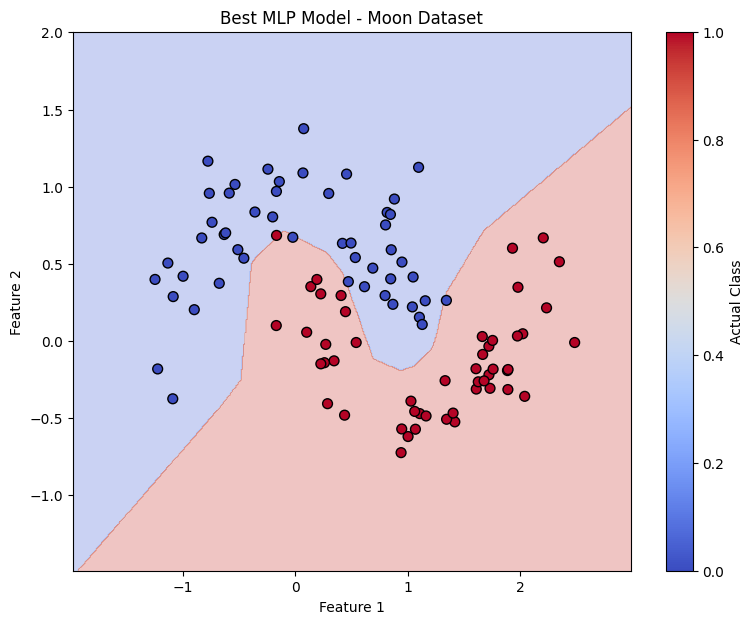

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Best model selected by GridSearchCV
best_model = grid_search.best_estimator_

# Create a mesh/grid covering the dataset
x_min = X[:, 0].min() - 0.5
x_max = X[:, 0].max() + 0.5
y_min = X[:, 1].min() - 0.5
y_max = X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Predict the class for every point in the grid
grid_points = np.c_[xx.ravel(), yy.ravel()] #number of points × number of features

Z = best_model.predict(grid_points)
Z = Z.reshape(xx.shape)

# --------------------------------------------------
# Plot
# --------------------------------------------------
plt.figure(figsize=(9, 7))

# Decision boundary: color regions according to the model's predictions.
plt.contourf(
    xx,
    yy,
    Z,
    cmap="coolwarm",
    alpha=0.3
)

# Test data
scatter = plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test,
    cmap="coolwarm",
    edgecolors="black",
    s=50
)

plt.title("Best MLP Model - Moon Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.colorbar(scatter, label="Actual Class")

plt.show()
